In [1]:
import pandas as pd

# Memuat dataset Iris dari path yang ditentukan
df = pd.read_csv('/content/Iris.csv')

# Menampilkan 5 baris pertama
display(df.head())

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [2]:
# Menampilkan informasi struktur dataset
print("Informasi Dataset:")
df.info()

# Menampilkan statistik deskriptif
print("\nStatistik Deskriptif:")
display(df.describe())

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB

Statistik Deskriptif:


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


### Tahap 1: Validasi Struktur Data
Kita akan memverifikasi bahwa dataset memiliki 150 sampel, 4 fitur utama (selain `Id`), dan 3 kelas target unik pada kolom `Species`.

In [3]:
# Memeriksa jumlah kelas unik dan jumlah sampel per kelas
fitur_utama = ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']

print(f"Jumlah sampel: {len(df)}")
print(f"Jumlah fitur utama: {len(fitur_utama)} {fitur_utama}")
print(f"Jumlah kelas unik: {df['Species'].nunique()}")
print("\nDistribusi sampel per kelas:")
print(df['Species'].value_counts())

Jumlah sampel: 150
Jumlah fitur utama: 4 ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']
Jumlah kelas unik: 3

Distribusi sampel per kelas:
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


### Tahap 2: Preprocessing
Di tahap ini kita akan melakukan normalisasi Z-score pada fitur numerik dan One-Hot Encoding pada label target (`Species`).

In [4]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
import pandas as pd
import numpy as np

# 1. Normalisasi Z-Score untuk fitur
scaler = StandardScaler()
fitur_normalisasi = scaler.fit_transform(df[fitur_utama])
df_fitur_normalisasi = pd.DataFrame(fitur_normalisasi, columns=fitur_utama)

# 2. One-Hot Encoding untuk label Species
encoder = OneHotEncoder(sparse_output=False) # Gunakan sparse=False untuk versi sklearn lama jika diperlukan
label_one_hot = encoder.fit_transform(df[['Species']])
kolom_one_hot = encoder.get_feature_names_out(['Species'])
df_label_one_hot = pd.DataFrame(label_one_hot, columns=kolom_one_hot)

# Menggabungkan hasil preprocessing
df_preprocessed = pd.concat([df_fitur_normalisasi, df_label_one_hot], axis=1)

print("Hasil Preprocessing (5 data pertama):")
display(df_preprocessed.head())

Hasil Preprocessing (5 data pertama):


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species_Iris-setosa,Species_Iris-versicolor,Species_Iris-virginica
0,-0.900681,1.032057,-1.341272,-1.312977,1.0,0.0,0.0
1,-1.143017,-0.124958,-1.341272,-1.312977,1.0,0.0,0.0
2,-1.385353,0.337848,-1.398138,-1.312977,1.0,0.0,0.0
3,-1.506521,0.106445,-1.284407,-1.312977,1.0,0.0,0.0
4,-1.021849,1.263460,-1.341272,-1.312977,1.0,0.0,0.0


### Tahap 3: Training
Di tahap ini kita akan membagi data menjadi set pelatihan dan pengujian (80:20), kemudian melatih model Softmax Regression.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score
import numpy as np

# Memisahkan fitur (X) dan label asli (y) untuk klasifikasi
# Karena Softmax Regression di sklearn dapat menangani label kategori secara langsung,
# kita bisa menggunakan kolom 'Species' asli sebagai target (y), atau menggunakan label biner jika diperlukan.
# Di sini kita akan menggunakan label kategori asli untuk mempermudah evaluasi standard.

X = df_preprocessed[fitur_utama]
y = df['Species']

# Split data menjadi 80% train dan 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

# Inisialisasi model Softmax Regression (Multinomial Logistic Regression)
# 'lbfgs' secara otomatis mendukung multinomial loss
model = LogisticRegression(multi_class='multinomial', solver='lbfgs', max_iter=200)

# Melatih model
model.fit(X_train, y_train)

# Melakukan prediksi pada data uji
y_pred = model.predict(X_test)

# Menampilkan hasil performa model
accuracy = accuracy_score(y_test, y_pred)
print(f"Akurasi Model: {accuracy * 100:.2f}%")
print("\nLaporan Klasifikasi:")
print(classification_report(y_test, y_pred))

Akurasi Model: 93.33%

Laporan Klasifikasi:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.90      0.90      0.90        10
 Iris-virginica       0.90      0.90      0.90        10

       accuracy                           0.93        30
      macro avg       0.93      0.93      0.93        30
   weighted avg       0.93      0.93      0.93        30



/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


### Tahap 4: Prediksi & Evaluasi
Di tahap ini kita akan mengevaluasi model lebih lanjut menggunakan Confusion Matrix untuk melihat kesalahan prediksi antar kelas secara visual.

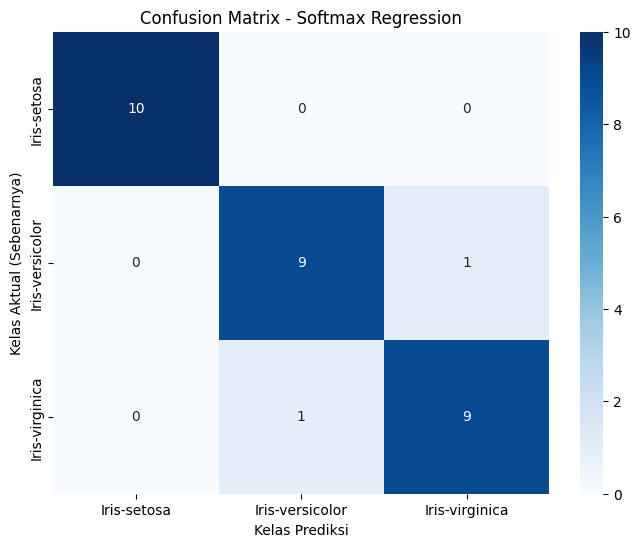

Analisis Kesalahan:
- Ada 1 data asli 'Iris-versicolor' yang salah diprediksi sebagai 'Iris-virginica'
- Ada 1 data asli 'Iris-virginica' yang salah diprediksi sebagai 'Iris-versicolor'


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Menghitung confusion matrix
cm = confusion_matrix(y_test, y_pred)
kelas_unik = model.classes_

# Membuat visualisasi heatmap untuk confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=kelas_unik, yticklabels=kelas_unik)
plt.title('Confusion Matrix - Softmax Regression')
plt.ylabel('Kelas Aktual (Sebenarnya)')
plt.xlabel('Kelas Prediksi')
plt.show()

# Analisis kesalahan
print("Analisis Kesalahan:")
for i, kelas_aktual in enumerate(kelas_unik):
    for j, kelas_prediksi in enumerate(kelas_unik):
        if i != j and cm[i, j] > 0:
            print(f"- Ada {cm[i, j]} data asli '{kelas_aktual}' yang salah diprediksi sebagai '{kelas_prediksi}'")

### Tambahan: K-Fold Cross-Validation
Untuk memastikan performa model stabil dan tidak bergantung pada pembagian split latih-uji tertentu, kita akan mengevaluasi model menggunakan 5-Fold Cross-Validation.

In [7]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

# Menyiapkan skema Stratified K-Fold (agar distribusi kelas seimbang di setiap lipatan/fold)
# Menggunakan K=5
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Melakukan cross-validation
akurasi_cv = cross_val_score(model, X, y, cv=cv, scoring='accuracy')

# Menampilkan hasil tiap fold dan rata-ratanya
print("Hasil Akurasi tiap Fold:")
for i, score in enumerate(akurasi_cv, 1):
    print(f"- Fold {i}: {score * 100:.2f}%")

print(f"\nRata-rata Akurasi CV: {akurasi_cv.mean() * 100:.2f}%")
print(f"Standar Deviasi CV: {akurasi_cv.std() * 100:.2f}%")

Hasil Akurasi tiap Fold:
- Fold 1: 100.00%
- Fold 2: 96.67%
- Fold 3: 90.00%
- Fold 4: 100.00%
- Fold 5: 90.00%

Rata-rata Akurasi CV: 95.33%
Standar Deviasi CV: 4.52%


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and wi

### Tambahan: 10-Fold Cross-Validation
Untuk pengujian yang lebih ketat, kita akan mengevaluasi model menggunakan 10-Fold Cross-Validation.

In [8]:
# Menyiapkan skema Stratified K-Fold dengan K=10
cv_10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# Melakukan cross-validation dengan K=10
akurasi_cv_10 = cross_val_score(model, X, y, cv=cv_10, scoring='accuracy')

# Menampilkan hasil tiap fold dan rata-ratanya
print("Hasil Akurasi tiap Fold (K=10):")
for i, score in enumerate(akurasi_cv_10, 1):
    print(f"- Fold {i}: {score * 100:.2f}%")

print(f"\nRata-rata Akurasi CV (K=10): {akurasi_cv_10.mean() * 100:.2f}%")
print(f"Standar Deviasi CV (K=10): {akurasi_cv_10.std() * 100:.2f}%")

Hasil Akurasi tiap Fold (K=10):
- Fold 1: 100.00%
- Fold 2: 100.00%
- Fold 3: 100.00%
- Fold 4: 93.33%
- Fold 5: 86.67%
- Fold 6: 93.33%
- Fold 7: 100.00%
- Fold 8: 100.00%
- Fold 9: 93.33%
- Fold 10: 86.67%

Rata-rata Akurasi CV (K=10): 95.33%
Standar Deviasi CV (K=10): 5.21%


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and wi